# Пример расчета прямого и обратного прохода при обучении сети.

<img src='images/ris0_1.png' width=600, heigth=440> <br>
<img src='images/ris0_2.png' width=600, heigth=440> <br>
<img src='images/ris0_3.png' width=600, heigth=440> <br>
<img src='images/ris1_1.png' width=600, heigth=440> <br>
<img src='images/ris1_2.png' width=600, heigth=440> <br>


# Открытие датасета

# Импорты
Нужно установить PyTorch 

In [1]:
import math
import csv
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import gridspec
%matplotlib inline


#---------
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
from torchvision import transforms
from torchvision.transforms.functional import normalize
import torchvision.datasets as dset

from torch.utils.data import Dataset, DataLoader
from torch.utils.data.sampler import SubsetRandomSampler, Sampler
from tqdm import tqdm
from sklearn.metrics import classification_report


In [2]:
#Возьмем данные из модуля datasets библиотеки Scikit-learn. Вначале загрузим их.
from sklearn import datasets
raw_data = datasets.load_wine()

In [3]:
# посмотрим на составляющие датасета
raw_data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [4]:
# определим тип данных нашего датасета
type(raw_data)

sklearn.utils._bunch.Bunch

In [5]:
# разбиение датасета на с цифрами на тестовый и обучающий
MNIST_train = torchvision.datasets.MNIST(root='./data', 
                                           train=True, 
                                           transform=transforms.ToTensor(),  
                                           download=True)
MNIST_test = torchvision.datasets.MNIST(root='./data', 
                                          train=False, 
                                          transform=transforms.ToTensor())


C:\Users\NKTKLN\AppData\Local\Temp\ipykernel_17568\357252736.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  ax[i].imshow(np.array(MNIST_train[i][0][0]), 'gray')


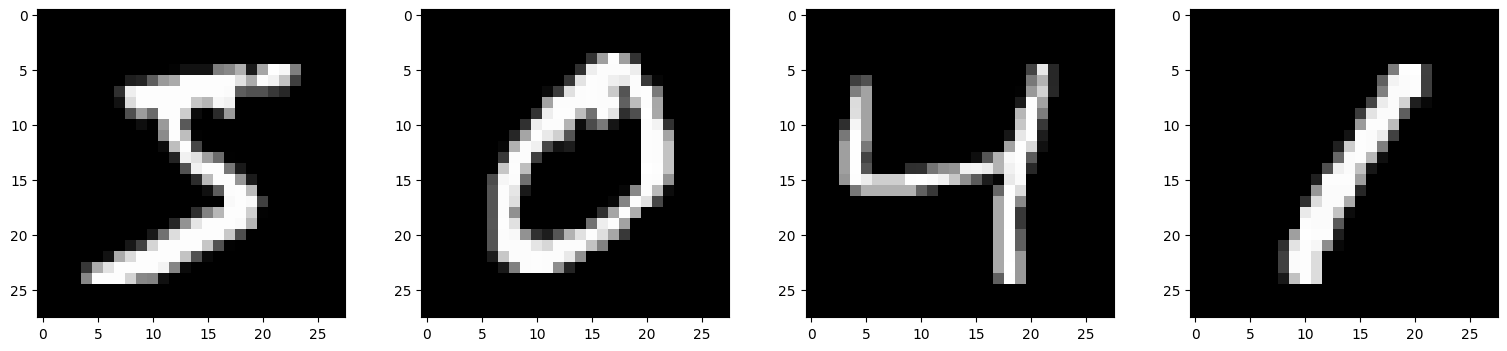

In [6]:
# отображение датасета с  цифрами
fig, gs = plt.figure(figsize=(19,4)), gridspec.GridSpec(1, 4) 
ax = []
for i in range(4):
    ax.append(fig.add_subplot(gs[i]))
    ax[i].imshow(np.array(MNIST_train[i][0][0]), 'gray')
plt.show()

In [7]:
# создание класса perceptron
class Perceptron(torch.nn.Module):
    def __init__(self, input_dim=784, num_layers=0,
            hidden_dim=64, output_dim=10, p=0.0, device='cpu'): 
        super(Perceptron, self).__init__()
        self.layers = torch.nn.Sequential()
        prev_size = input_dim 
        for i in range(num_layers):
            self.layers.add_module('layer{}'.format(i), torch.nn.Linear(prev_size, hidden_dim)) 
            self.layers.add_module('relu{}'.format(i), torch.nn.ReLU())
            self.layers.add_module('dropout{}'.format(i), torch.nn.Dropout(p=p)) 
            prev_size = hidden_dim
        self.layers.add_module('classifier',
            torch.nn.Linear(prev_size, output_dim))
        self.to(device)

    def forward(self, input):
        return self.layers(input)


In [8]:
# это объект, обозначающий устройство, на котором размещен или будет размещен torch.Tensor \
# Torch.device содержит тип устройства («процессор» или « cuda»)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
device


device(type='cpu')

In [9]:
# Создание модели без внутренних слоев 
model = Perceptron(device=device) 
model

Perceptron(
  (layers): Sequential(
    (classifier): Linear(in_features=784, out_features=10, bias=True)
  )
)

In [10]:

model = Perceptron(num_layers=5, device=device) 
model

Perceptron(
  (layers): Sequential(
    (layer0): Linear(in_features=784, out_features=64, bias=True)
    (relu0): ReLU()
    (dropout0): Dropout(p=0.0, inplace=False)
    (layer1): Linear(in_features=64, out_features=64, bias=True)
    (relu1): ReLU()
    (dropout1): Dropout(p=0.0, inplace=False)
    (layer2): Linear(in_features=64, out_features=64, bias=True)
    (relu2): ReLU()
    (dropout2): Dropout(p=0.0, inplace=False)
    (layer3): Linear(in_features=64, out_features=64, bias=True)
    (relu3): ReLU()
    (dropout3): Dropout(p=0.0, inplace=False)
    (layer4): Linear(in_features=64, out_features=64, bias=True)
    (relu4): ReLU()
    (dropout4): Dropout(p=0.0, inplace=False)
    (classifier): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [11]:
# процедура терстирования модели 
def testing(model, dataset):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)
    pred = []
    real = []
    for x, y in tqdm(generator, leave=False):
        x = x.view([-1, 784]).to(device) 
        y = y.to(device)
        pred.extend(torch.argmax(model(x), dim=-1).cpu().numpy().tolist()) 
        real.extend(y.cpu().numpy().tolist())
    
    return np.mean(np.array(real) == np.array(pred)), classification_report(real, pred)


In [12]:
# процедура тренировки модели
def trainer(model, dataset, loss_function, optimizer, epochs): 
    for epoch in tqdm(range(epochs), leave=False):
        generator = torch.utils.data.DataLoader(dataset, batch_size=64,
            shuffle=True)

        for x, y in tqdm(generator, leave=False):
            optimizer.zero_grad() 
            x = x.view([-1, 784]).to(device) 
            y = y.to(device)
            output = model(x)
            loss = loss_function(output, y)
            loss.backward()
            optimizer.step()


In [13]:
model = Perceptron(num_layers=0, device=device)


In [14]:
# Результат, получаемый от необученной модели.
_ = model.eval()
acc, report = testing(model, MNIST_test) 
print(report)

              precision    recall  f1-score   support

           0       0.04      0.01      0.01       980
           1       0.10      0.33      0.15      1135
           2       0.07      0.04      0.05      1032
           3       0.20      0.01      0.01      1010
           4       0.12      0.19      0.14       982
           5       0.25      0.07      0.11       892
           6       0.00      0.00      0.00       958
           7       0.06      0.16      0.08      1028
           8       0.05      0.00      0.01       974
           9       0.03      0.01      0.02      1009

    accuracy                           0.09     10000
   macro avg       0.09      0.08      0.06     10000
weighted avg       0.09      0.09      0.06     10000



In [15]:
# Обучение модели
_ = model.train()
trainer(model=model,
    dataset=MNIST_train,
    loss_function=torch.nn.CrossEntropyLoss(),
    optimizer=torch.optim.Adam(model.parameters(), lr=0.001), 
    epochs=4)


In [16]:
# Результат обучения классификатора
_ = model.eval()
acc, report = testing(model, MNIST_test) 
print(report)

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       980
           1       0.97      0.98      0.97      1135
           2       0.93      0.90      0.91      1032
           3       0.91      0.90      0.91      1010
           4       0.94      0.92      0.93       982
           5       0.91      0.87      0.89       892
           6       0.93      0.96      0.94       958
           7       0.94      0.91      0.92      1028
           8       0.88      0.88      0.88       974
           9       0.87      0.93      0.90      1009

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



Задание: С помощью нейронной сети классифицировать вина по качеству. Датасет взять из третьей работы. Разбить датасет на два класса по качеству вина. Качество вина до пяти включительно определить как первый класс, свыше пяти - как второй.
Представить основные показатели метода. Сравнить результат классификации с результатом из третьей работы.

In [17]:
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from numpy.typing import NDArray
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [18]:
def evaluate_classification_models(
    predictions: dict[str, NDArray[np.float64]], y: NDArray[np.float64]
) -> pd.DataFrame:
    """Evaluate multiple classification model predictions on the provided dataset.

    Args:
        predictions (dict[str, NDArray[np.float64]]): Dictionary mapping model names
            to predicted target arrays for the dataset.
        y (NDArray[np.float64]): True binary target values of shape (n_samples,).

    Returns:
        pd.DataFrame: DataFrame containing classification metrics — Accuracy, Precision,
            Recall, F1-score, and ROC AUC — for each model. Columns correspond to
            model names, rows correspond to the metric names.
    """
    evaluations = pd.DataFrame(
        columns=predictions.keys(),
        index=["Accuracy", "Precision", "Recall", "F1-score"],
    )

    for name, y_pred in predictions.items():
        accuracy = accuracy_score(y, y_pred)
        precision = precision_score(y, y_pred)
        recall = recall_score(y, y_pred)
        f1 = f1_score(y, y_pred)

        evaluations.loc[:, name] = [accuracy, precision, recall, f1]

    return evaluations.astype(float)

In [19]:
def plot_confusion_matrices(
    predictions: dict[str, NDArray[np.int64]],
    y_true: NDArray[np.int64],
    n_cols: int = 2,
) -> None:
    """Plot confusion matrices for multiple classification models.

    Each confusion matrix compares the true labels to predictions from one model.
    The plots are arranged in a grid layout for easy comparison.

    Args:
        predictions (dict[str, NDArray[np.int64]]): A dictionary mapping model names to
            their predicted labels (1D array of shape (n_samples,)).
        y_true (NDArray[np.int64]): True class labels (1D array of shape (n_samples,)).
        n_cols (int, optional): Number of columns in the subplot grid layout.
            Default is 2.
    """
    n_models = len(predictions)
    n_cols = min(n_models, n_cols)
    n_rows = ceil(n_models / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, (name, y_pred) in zip(axes, predictions.items(), strict=False):
        conf_matrix = confusion_matrix(y_true, y_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_xlabel("Predicted Labels")
        ax.set_ylabel("True Labels")
        ax.set_title(name)

    for i in range(n_models, len(axes)):
        fig.delaxes(axes[i])

    plt.tight_layout()
    plt.show() 

In [20]:
df = pd.read_csv("winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [21]:
df["status"] = (df["quality"] >= 7).astype(int)

features = [
    'fixed acidity', 
    'volatile acidity', 
    'citric acid', 
    'residual sugar',
    'chlorides', 
    'free sulfur dioxide', 
    'total sulfur dioxide', 
    'density',
    'pH', 
    'sulphates', 
    'alcohol'
]

X, y = df[features], df["status"]
X, y = X.to_numpy(), y.to_numpy()

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

perceptron_model = Perceptron(
    input_dim=X_train.shape[1],
    num_layers=3,
    hidden_dim=64,
    output_dim=2,
    p=0.3,
    device=device
)


def train_model(model, X, y, epochs=50, batch_size=32, lr=0.001):
    dataset = torch.utils.data.TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()


def predict_model(model, X):
    model.eval()
    X = torch.tensor(X, dtype=torch.float32).to(device)
    with torch.no_grad():
        out = model(X)
        preds = torch.argmax(out, dim=1)
    return preds.cpu().numpy()

In [43]:
train_model(perceptron_model, X_train, y_train, epochs=200, batch_size=32, lr=0.003)

knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [44]:
preds = {
    "kNN": knn_model.predict(X_val),
    "perceptron": predict_model(perceptron_model, X_val),
}

In [45]:
evaluate_classification_models(preds, y_val)

,kNN,perceptron
Accuracy,0.893750,0.937500
Precision,0.636364,0.780488
Recall,0.488372,0.744186
F1-score,0.552632,0.761905


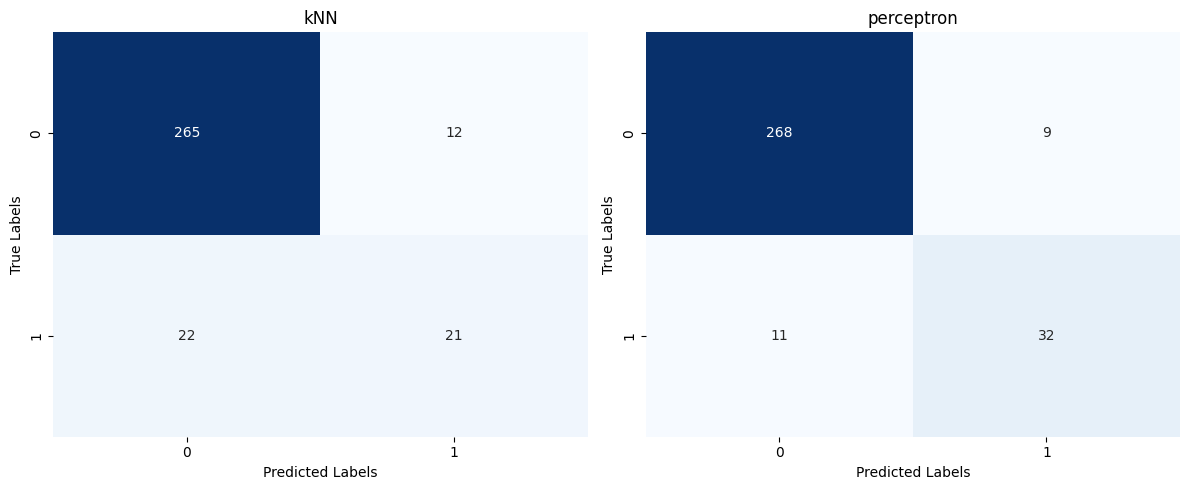

In [46]:
plot_confusion_matrices(preds, y_val)